In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

In [ ]:
from google.colab import files
uploaded = files.upload()          # choose train.csv

df = pd.read_csv("train.csv")
print(df.shape)
df.head()

Saving train.csv to train.csv
(45593, 20)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [ ]:
#Exploratory Data Analysis
df.info() #summary of dataset
print(df.describe(include="all").T.head(25)) #To get statistics
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["ID"].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  45593 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [ ]:
# 3.1 Strip whitespace in every text column and convert "NaN" strings to real nulls
obj_cols = df.select_dtypes(include="object").columns
for c in obj_cols:
    df[c] = df[c].str.strip()
df = df.replace("NaN", np.nan)

# 3.2 Target: "(min) 24" -> 24
df["Time_taken(min)"] = (
    df["Time_taken(min)"].astype(str).str.extract(r"(\d+)")[0].astype(float)
)

# 3.3 Weather: "conditions Sunny" -> "Sunny"
df["Weatherconditions"] = (
    df["Weatherconditions"].str.replace("conditions", "", regex=False).str.strip()
)

# 3.4 Numeric columns stored as text -> numbers
for c in ["Delivery_person_Age", "Delivery_person_Ratings", "multiple_deliveries"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# 3.5 Drop duplicate orders (if any)
df = df.drop_duplicates(subset="ID").reset_index(drop=True)

print(df.isna().sum())
print(df["Time_taken(min)"].describe())

ID                                0
Delivery_person_ID                0
Delivery_person_Age            1854
Delivery_person_Ratings        1908
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Order_Date                        0
Time_Orderd                    1731
Time_Order_picked                 0
Weatherconditions                 0
Road_traffic_density            601
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries             993
Festival                        228
City                           1200
Time_taken(min)                   0
dtype: int64
count    45593.000000
mean        26.294607
std          9.383806
min         10.000000
25%         19.000000
50%         26.000000
75%         32.000000
max         54.000000
Name: Time_taken(min), dtype: float64


In [ ]:
#Data validation
n0 = len(df)

coord_cols = ["Restaurant_latitude", "Restaurant_longitude",
              "Delivery_location_latitude", "Delivery_location_longitude"]

# Indian coordinates are all positive; zeros/negatives are data errors
bad_coord = (df[coord_cols] <= 0).any(axis=1)
# Ratings must be within 0-5
bad_rating = df["Delivery_person_Ratings"] > 5

print("Invalid coordinates:", bad_coord.sum())
print("Ratings above 5:", bad_rating.sum())

df = df[~(bad_coord | bad_rating)].reset_index(drop=True)
print(f"Rows: {n0} -> {len(df)}")

Invalid coordinates: 4071
Ratings above 5: 53
Rows: 45593 -> 41498


In [ ]:
# 5.1 Haversine distance (km) between restaurant and delivery location
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(
    df["Restaurant_latitude"], df["Restaurant_longitude"],
    df["Delivery_location_latitude"], df["Delivery_location_longitude"],
)

# 5.2 Parse dates and times
df["Order_Date"] = pd.to_datetime(df["Order_Date"], format="%d-%m-%Y", errors="coerce")
t_order  = pd.to_datetime(df["Time_Orderd"], format="%H:%M:%S", errors="coerce")
t_picked = pd.to_datetime(df["Time_Order_picked"], format="%H:%M:%S", errors="coerce")

# 5.3 Preparation time (minutes) = pickup - order; negative means it crossed midnight
prep = (t_picked - t_order).dt.total_seconds() / 60
prep = prep.where(prep >= 0, prep + 24 * 60)  #if it crosses midnight
df["prep_time_min"] = prep

# 5.4 Time-based features
df["order_hour"] = t_order.dt.hour
df["order_dayofweek"] = df["Order_Date"].dt.dayofweek      # Mon=0 ... Sun=6
df["is_weekend"] = (df["order_dayofweek"] >= 5).astype(float)
df.loc[df["order_dayofweek"].isna(), "is_weekend"] = np.nan

df[["distance_km", "prep_time_min", "order_hour", "order_dayofweek", "is_weekend"]].describe()

,distance_km,prep_time_min,order_hour,order_dayofweek,is_weekend
count,41498.000000,40197.000000,40197.000000,41498.000000,41498.000000
mean,9.719726,9.979476,17.420653,2.994192,0.275387
std,5.602818,4.087583,4.815845,1.970660,0.446714
min,1.465067,5.000000,0.000000,0.000000,0.000000
25%,4.657655,5.000000,15.000000,1.000000,0.000000
50%,9.193021,10.000000,19.000000,3.000000,0.000000
75%,13.680920,15.000000,21.000000,5.000000,1.000000
max,20.969489,15.000000,23.000000,6.000000,1.000000


In [ ]:
for c in ["distance_km", "prep_time_min", "Time_taken(min)", "Delivery_person_Age"]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[c] < lo) | (df[c] > hi)).sum()
    print(f"{c:22s} fences=({lo:.1f}, {hi:.1f})  outliers={n_out}")

distance_km            fences=(-8.9, 27.2)  outliers=0
prep_time_min          fences=(-10.0, 30.0)  outliers=0
Time_taken(min)        fences=(-0.5, 51.5)  outliers=243
Delivery_person_Age    fences=(10.0, 50.0)  outliers=0


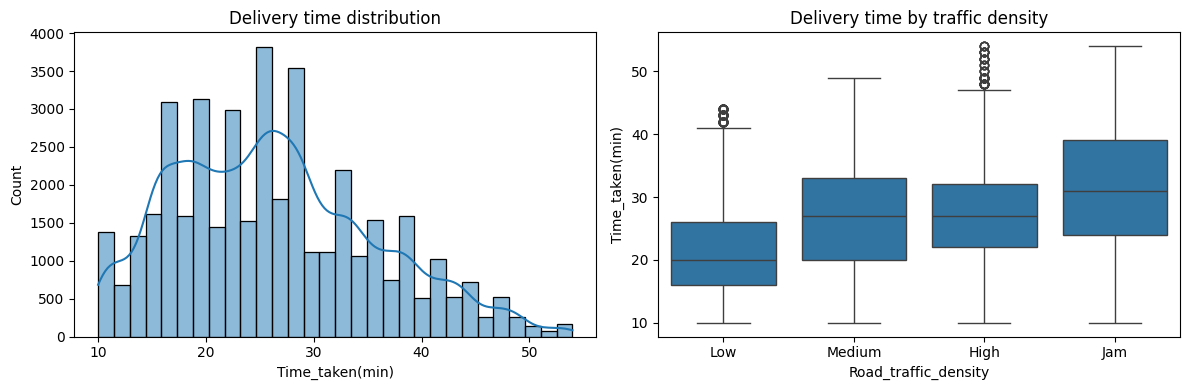

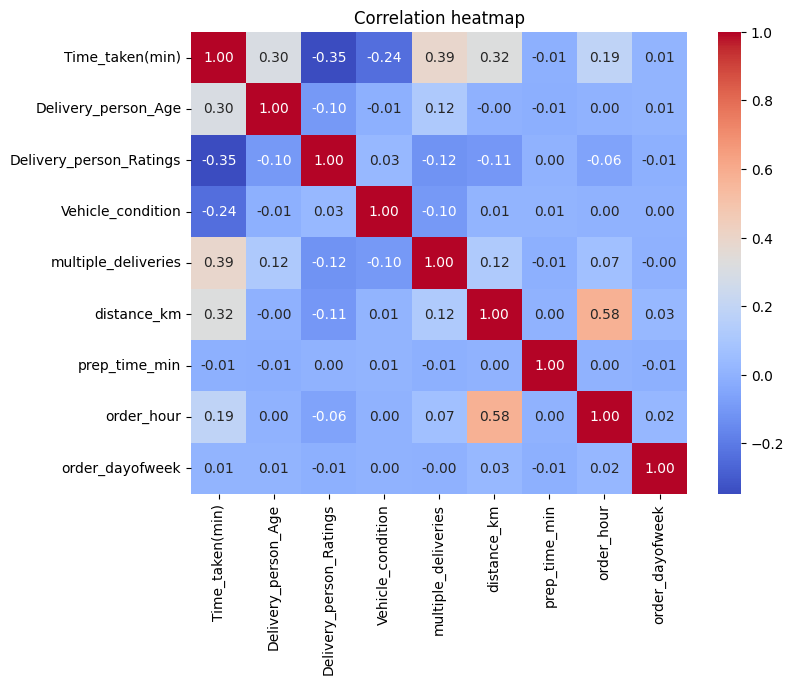

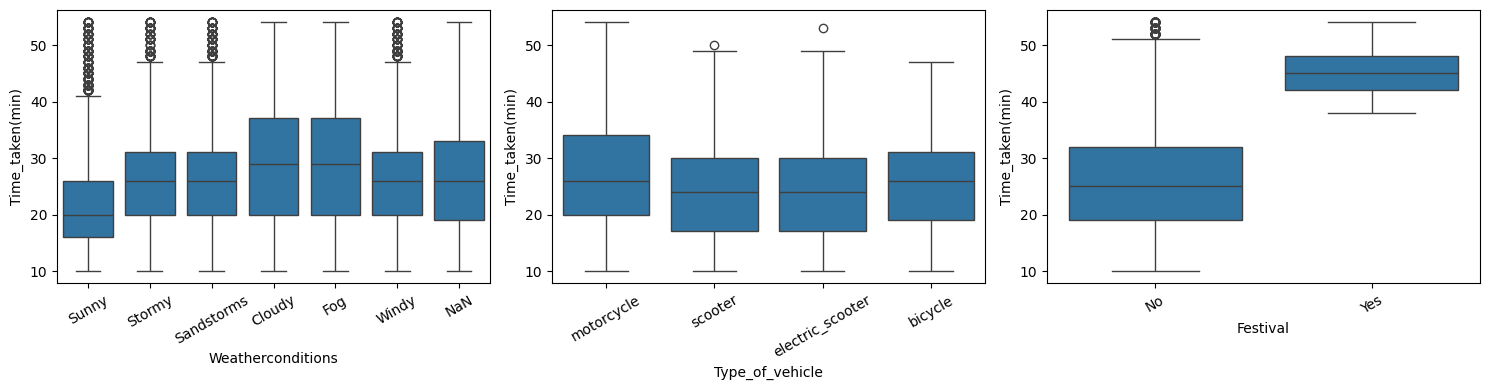

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Time_taken(min)"], bins=30, kde=True, ax=ax[0])
ax[0].set_title("Delivery time distribution")
sns.boxplot(data=df, x="Road_traffic_density", y="Time_taken(min)",
            order=["Low", "Medium", "High", "Jam"], ax=ax[1])
ax[1].set_title("Delivery time by traffic density")
plt.tight_layout(); plt.show()

num_for_corr = ["Time_taken(min)", "Delivery_person_Age", "Delivery_person_Ratings",
                "Vehicle_condition", "multiple_deliveries", "distance_km",
                "prep_time_min", "order_hour", "order_dayofweek"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_for_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap"); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["Weatherconditions", "Type_of_vehicle", "Festival"]):
    sns.boxplot(data=df, x=col, y="Time_taken(min)", ax=a)
    a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

In [ ]:
num_cols = ["Delivery_person_Age", "Delivery_person_Ratings", "Vehicle_condition",
            "multiple_deliveries", "distance_km", "prep_time_min",
            "order_hour", "order_dayofweek", "is_weekend"]
ord_cols = ["Road_traffic_density"]
nom_cols = ["Weatherconditions", "Type_of_vehicle", "Type_of_order", "City", "Festival"]

X = df[num_cols + ord_cols + nom_cols]
y_reg = df["Time_taken(min)"]

# Used ONLY to keep the Delayed / On-time proportions equal in both splits
strat = (y_reg > y_reg.median()).astype(int)

X_train, X_test, y_reg_train, y_reg_test = train_test_split(
    X, y_reg, test_size=0.2, random_state=RANDOM_STATE, stratify=strat
)

# Classification target: threshold from the TRAINING set only
threshold = y_reg_train.median()
y_clf_train = (y_reg_train > threshold).astype(int)   # 1 = Delayed, 0 = On-time
y_clf_test  = (y_reg_test  > threshold).astype(int)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Median threshold (min):", threshold)
print("Train class balance:\n", y_clf_train.value_counts(normalize=True).round(3))
print("Test class balance:\n", y_clf_test.value_counts(normalize=True).round(3))

Train: (33198, 15)  Test: (8300, 15)
Median threshold (min): 26.0
Train class balance:
 Time_taken(min)
0    0.544
1    0.456
Name: proportion, dtype: float64
Test class balance:
 Time_taken(min)
0    0.544
1    0.456
Name: proportion, dtype: float64


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

traffic_order = [["Low", "Medium", "High", "Jam"]]

# ---- Version for the Decision Tree: impute + encode, no scaling ----
tree_pre = ColumnTransformer(
    [
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("ord", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("enc", OrdinalEncoder(categories=traffic_order)),
        ]), ord_cols),
        ("nom", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("enc", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), nom_cols),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

# ---- Version for Linear Regression: impute + encode + scale ----
lr_pre = ColumnTransformer(
    [
        ("num", Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("sc", StandardScaler()),
        ]), num_cols),
        ("ord", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("enc", OrdinalEncoder(categories=traffic_order)),
            ("sc", StandardScaler()),
        ]), ord_cols),
        ("nom", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("enc", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
        ]), nom_cols),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

# Fit on TRAIN only, then apply to test
X_train_tree = tree_pre.fit_transform(X_train)
X_test_tree  = tree_pre.transform(X_test)

X_train_lr = lr_pre.fit_transform(X_train)
X_test_lr  = lr_pre.transform(X_test)

In [ ]:
print("Tree features :", X_train_tree.shape, X_test_tree.shape)
print("LR features   :", X_train_lr.shape,  X_test_lr.shape)
print("Missing values left:", X_train_tree.isna().sum().sum(), X_test_lr.isna().sum().sum())
print("\nFeature names:\n", list(X_train_tree.columns))

# Scaled columns should have mean ~0, std ~1 on TRAIN
print(X_train_lr[num_cols].mean().round(2).head())
X_train_lr.head()

Tree features : (33198, 30) (8300, 30)
LR features   : (33198, 25) (8300, 25)
Missing values left: 0 0

Feature names:
 ['Delivery_person_Age', 'Delivery_person_Ratings', 'Vehicle_condition', 'multiple_deliveries', 'distance_km', 'prep_time_min', 'order_hour', 'order_dayofweek', 'is_weekend', 'Road_traffic_density', 'Weatherconditions_Cloudy', 'Weatherconditions_Fog', 'Weatherconditions_NaN', 'Weatherconditions_Sandstorms', 'Weatherconditions_Stormy', 'Weatherconditions_Sunny', 'Weatherconditions_Windy', 'Type_of_vehicle_bicycle', 'Type_of_vehicle_electric_scooter', 'Type_of_vehicle_motorcycle', 'Type_of_vehicle_scooter', 'Type_of_order_Buffet', 'Type_of_order_Drinks', 'Type_of_order_Meal', 'Type_of_order_Snack', 'City_Metropolitian', 'City_Semi-Urban', 'City_Urban', 'Festival_No', 'Festival_Yes']
Delivery_person_Age        0.0
Delivery_person_Ratings    0.0
Vehicle_condition          0.0
multiple_deliveries        0.0
distance_km               -0.0
dtype: float64


,Delivery_person_Age,Delivery_person_Ratings,Vehicle_condition,multiple_deliveries,distance_km,prep_time_min,order_hour,order_dayofweek,is_weekend,Road_traffic_density,Weatherconditions_Fog,Weatherconditions_NaN,Weatherconditions_Sandstorms,Weatherconditions_Stormy,Weatherconditions_Sunny,Weatherconditions_Windy,Type_of_vehicle_electric_scooter,Type_of_vehicle_motorcycle,Type_of_vehicle_scooter,Type_of_order_Drinks,Type_of_order_Meal,Type_of_order_Snack,City_Semi-Urban,City_Urban,Festival_Yes
33273,-1.331813,0.202464,1.183119,-1.328481,-0.069334,1.248294,1.164318,-1.013091,-0.616884,-1.101638,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
17544,0.783970,-3.547798,-0.019195,2.202435,1.868125,1.248294,0.743706,-1.013091,-0.616884,1.303688,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
18241,1.665546,0.827508,-1.221508,0.436977,-0.370390,0.001990,0.323093,-0.505146,-0.616884,1.303688,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
41313,0.431340,0.202464,1.183119,-1.328481,-0.652239,1.248294,-1.149051,0.510746,-0.616884,0.501913,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
30742,0.783970,-0.422580,-0.019195,-1.328481,-1.205688,0.001990,-1.990276,-0.505146,-0.616884,-1.101638,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0


In [ ]:
import time
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lin_reg = LinearRegression()

t0 = time.perf_counter()
lin_reg.fit(X_train_lr, y_reg_train)
lr_train_time = time.perf_counter() - t0

print(f"Training time: {lr_train_time:.4f} s")
print("Intercept:", round(lin_reg.intercept_, 3))

Training time: 0.0535 s
Intercept: 29.178


In [ ]:
def reg_metrics(y_true, y_pred):
    return {
        "MAE (min)":  mean_absolute_error(y_true, y_pred),
        "RMSE (min)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2":         r2_score(y_true, y_pred),
    }

y_pred_lr_train = lin_reg.predict(X_train_lr)
y_pred_lr_test  = lin_reg.predict(X_test_lr)

lr_results = pd.DataFrame({
    "Train": reg_metrics(y_reg_train, y_pred_lr_train),
    "Test":  reg_metrics(y_reg_test,  y_pred_lr_test),
}).round(3)
lr_results

,Train,Test
MAE (min),4.849,4.840
RMSE (min),6.072,6.033
R2,0.583,0.580


In [ ]:
from sklearn.model_selection import cross_val_score

cv_r2 = cross_val_score(LinearRegression(), X_train_lr, y_reg_train, cv=5, scoring="r2")
print("5-fold CV R2:", cv_r2.round(3), " mean =", cv_r2.mean().round(3))

5-fold CV R2: [0.589 0.584 0.583 0.575 0.578]  mean = 0.582


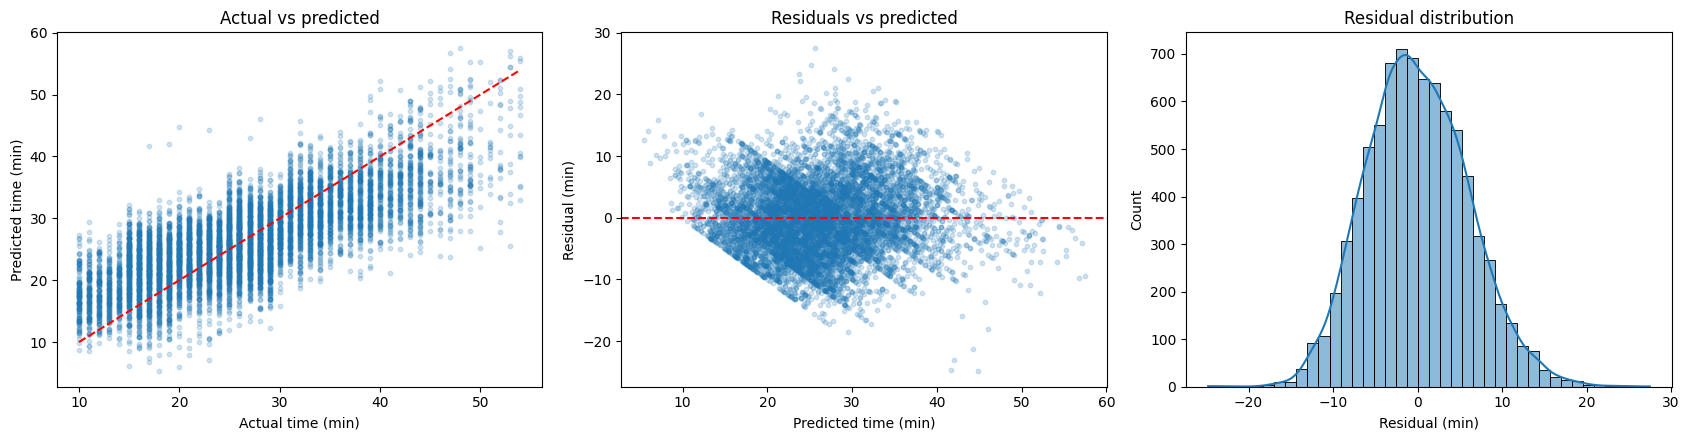

In [ ]:
resid = y_reg_test - y_pred_lr_test

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# Actual vs predicted
ax[0].scatter(y_reg_test, y_pred_lr_test, alpha=0.2, s=10)
lims = [y_reg_test.min(), y_reg_test.max()]
ax[0].plot(lims, lims, "r--")
ax[0].set(xlabel="Actual time (min)", ylabel="Predicted time (min)",
          title="Actual vs predicted")

# Residuals vs predicted (look for a flat, even band with no curve or funnel)
ax[1].scatter(y_pred_lr_test, resid, alpha=0.2, s=10)
ax[1].axhline(0, color="r", linestyle="--")
ax[1].set(xlabel="Predicted time (min)", ylabel="Residual (min)",
          title="Residuals vs predicted")

# Residual distribution (should be roughly bell-shaped, centred at 0)
sns.histplot(resid, bins=40, kde=True, ax=ax[2])
ax[2].set(xlabel="Residual (min)", title="Residual distribution")

plt.tight_layout(); plt.show()

                         feature  coefficient
                 City_Semi-Urban        9.794
                    Festival_Yes        9.568
         Weatherconditions_Sunny       -6.272
           Weatherconditions_NaN        3.490
            Road_traffic_density        2.982
        Weatherconditions_Stormy       -2.871
    Weatherconditions_Sandstorms       -2.808
         Weatherconditions_Windy       -2.658
             Delivery_person_Age        2.257
         Delivery_person_Ratings       -2.222
                     distance_km        2.062
                      City_Urban       -1.923
               Vehicle_condition       -1.811
             multiple_deliveries        1.661
         Type_of_vehicle_scooter       -0.748
                      order_hour       -0.520
      Type_of_vehicle_motorcycle       -0.199
             Type_of_order_Snack        0.122
Type_of_vehicle_electric_scooter        0.119
              Type_of_order_Meal        0.115
                      is_weekend  

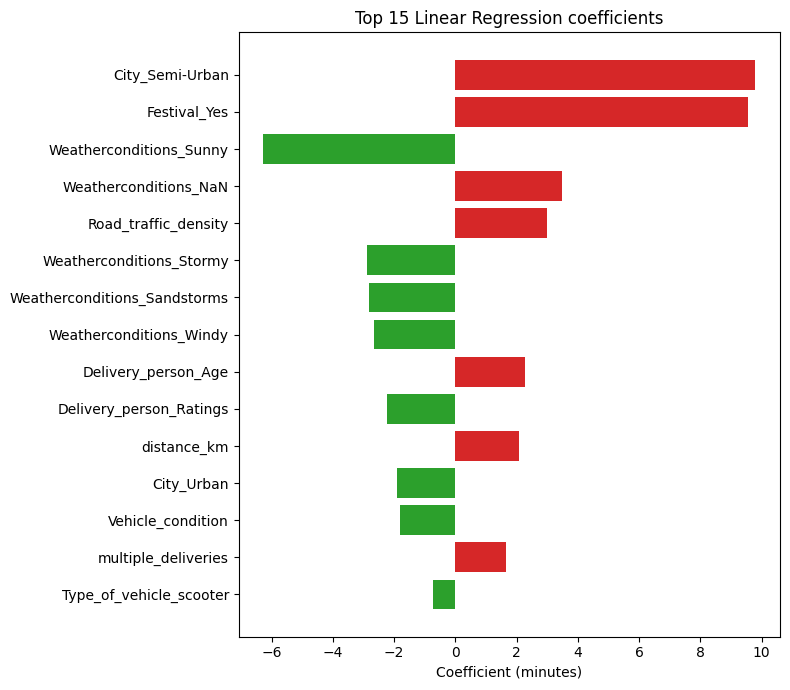

In [ ]:
coef_df = pd.DataFrame({
    "feature": X_train_lr.columns,
    "coefficient": lin_reg.coef_,
}).assign(abs_coef=lambda d: d["coefficient"].abs()) \
 .sort_values("abs_coef", ascending=False)

print(coef_df[["feature", "coefficient"]].round(3).to_string(index=False))

plt.figure(figsize=(8, 7))
top = coef_df.head(15).iloc[::-1]
plt.barh(top["feature"], top["coefficient"],
         color=np.where(top["coefficient"] > 0, "tab:red", "tab:green"))
plt.xlabel("Coefficient (minutes)")
plt.title("Top 15 Linear Regression coefficients")
plt.tight_layout(); plt.show()

In [ ]:
scaler = lr_pre.named_transformers_["num"].named_steps["sc"]
per_unit = pd.Series(lin_reg.coef_[:len(num_cols)] / scaler.scale_, index=num_cols)
print("Effect per 1 original unit (min):")
print(per_unit.round(3))

Effect per 1 original unit (min):
Delivery_person_Age        0.398
Delivery_person_Ratings   -6.943
Vehicle_condition         -2.178
multiple_deliveries        2.932
distance_km                0.368
prep_time_min             -0.002
order_hour                -0.109
order_dayofweek            0.040
is_weekend                -0.231
dtype: float64


In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

Xc = add_constant(X_train_lr)
vif = pd.DataFrame({
    "feature": Xc.columns,
    "VIF": [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])],
}).query("feature != 'const'").sort_values("VIF", ascending=False)
vif.round(2).head(15)

,feature,VIF
18,Type_of_vehicle_motorcycle,275.21
19,Type_of_vehicle_scooter,251.03
17,Type_of_vehicle_electric_scooter,85.83
8,order_dayofweek,2.60
9,is_weekend,2.60
3,Vehicle_condition,1.76
14,Weatherconditions_Stormy,1.68
13,Weatherconditions_Sandstorms,1.68
11,Weatherconditions_Fog,1.68
15,Weatherconditions_Sunny,1.67


In [ ]:
from sklearn.metrics import accuracy_score, f1_score

# Convert predicted minutes into Delayed (1) / On-time (0) using the same threshold
y_pred_lr_class = (y_pred_lr_test > threshold).astype(int)

lr_clf_acc = accuracy_score(y_clf_test, y_pred_lr_class)
lr_clf_f1  = f1_score(y_clf_test, y_pred_lr_class)

print(f"Linear Regression as classifier -> Accuracy: {lr_clf_acc:.3f}, F1: {lr_clf_f1:.3f}")

Linear Regression as classifier -> Accuracy: 0.775, F1: 0.762


##Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, classification_report)

dt_full = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_full.fit(X_train_tree, y_clf_train)

print("Depth:", dt_full.get_depth(), " Leaves:", dt_full.get_n_leaves())
print("Train accuracy:", round(dt_full.score(X_train_tree, y_clf_train), 4))
print("Test accuracy :", round(dt_full.score(X_test_tree,  y_clf_test), 4))

Depth: 32  Leaves: 4502
Train accuracy: 1.0
Test accuracy : 0.7988


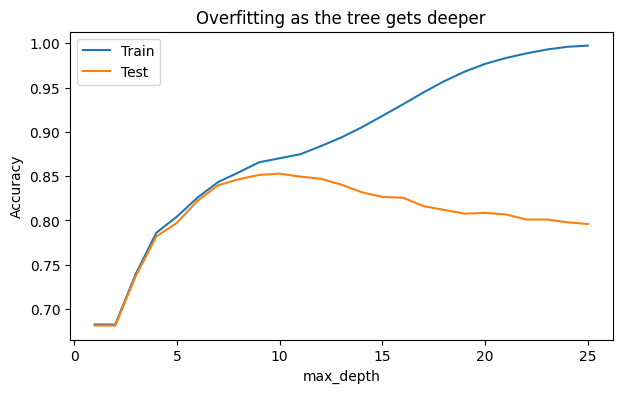

In [ ]:
depths = range(1, 26)
tr, te = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train_tree, y_clf_train)
    tr.append(m.score(X_train_tree, y_clf_train))
    te.append(m.score(X_test_tree, y_clf_test))

plt.figure(figsize=(7, 4))
plt.plot(depths, tr, label="Train"); plt.plot(depths, te, label="Test")
plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.legend()
plt.title("Overfitting as the tree gets deeper"); plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [4, 6, 8, 10, 12, 15, None],
    "min_samples_split": [2, 10, 50],
    "min_samples_leaf": [1, 5, 20],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid,
    cv=cv,
    scoring="f1",        # F1 on the Delayed class; use "accuracy" if you prefer
    n_jobs=-1,
    verbose=1,
)

t0 = time.perf_counter()
grid.fit(X_train_tree, y_clf_train)
dt_train_time = time.perf_counter() - t0

print("Best parameters:", grid.best_params_)
print("Best CV F1:", round(grid.best_score_, 4))
print(f"Tuning time: {dt_train_time:.1f} s")

Fitting 5 folds for each of 126 candidates, totalling 630 fits
Best parameters: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 50}
Best CV F1: 0.836
Tuning time: 79.8 s


In [ ]:
dt = grid.best_estimator_

# Top 5 parameter combinations
cv_res = pd.DataFrame(grid.cv_results_)
cv_res[["params", "mean_test_score", "std_test_score"]] \
    .sort_values("mean_test_score", ascending=False).head(5)

,params,mean_test_score,std_test_score
95,"{'criterion': 'entropy', 'max_depth': 10, 'min...",0.836013,0.005039
92,"{'criterion': 'entropy', 'max_depth': 10, 'min...",0.835691,0.006347
98,"{'criterion': 'entropy', 'max_depth': 10, 'min...",0.835070,0.006478
35,"{'criterion': 'gini', 'max_depth': 10, 'min_sa...",0.834829,0.005880
97,"{'criterion': 'entropy', 'max_depth': 10, 'min...",0.834718,0.005910


In [ ]:
y_pred_dt   = dt.predict(X_test_tree)
y_proba_dt  = dt.predict_proba(X_test_tree)[:, 1]

dt_metrics = {
    "Accuracy":  accuracy_score(y_clf_test, y_pred_dt),
    "Precision": precision_score(y_clf_test, y_pred_dt),
    "Recall":    recall_score(y_clf_test, y_pred_dt),
    "F1-score":  f1_score(y_clf_test, y_pred_dt),
    "ROC-AUC":   roc_auc_score(y_clf_test, y_proba_dt),
}
print(pd.Series(dt_metrics).round(4))
print("\nTrain accuracy:", round(dt.score(X_train_tree, y_clf_train), 4))
print("Test accuracy :", round(dt.score(X_test_tree, y_clf_test), 4))
print("\n", classification_report(y_clf_test, y_pred_dt, target_names=["On-time", "Delayed"]))

Accuracy     0.8551
Precision    0.8757
Recall       0.7949
F1-score     0.8333
ROC-AUC      0.9315
dtype: float64

Train accuracy: 0.8645
Test accuracy : 0.8551

               precision    recall  f1-score   support

     On-time       0.84      0.91      0.87      4517
     Delayed       0.88      0.79      0.83      3783

    accuracy                           0.86      8300
   macro avg       0.86      0.85      0.85      8300
weighted avg       0.86      0.86      0.85      8300



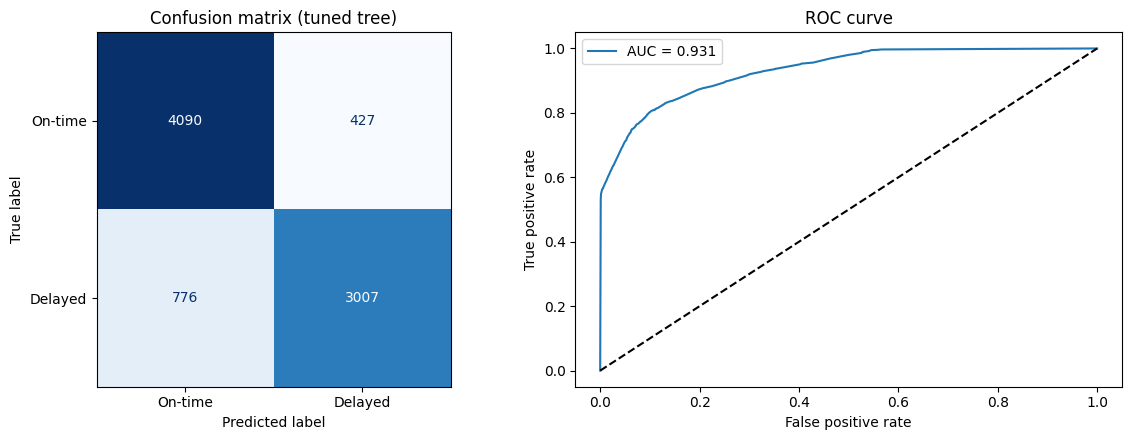

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ConfusionMatrixDisplay(confusion_matrix(y_clf_test, y_pred_dt),
                       display_labels=["On-time", "Delayed"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix (tuned tree)")

fpr, tpr, _ = roc_curve(y_clf_test, y_proba_dt)
ax[1].plot(fpr, tpr, label=f"AUC = {dt_metrics['ROC-AUC']:.3f}")
ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
ax[1].legend()

plt.tight_layout(); plt.show()

Delivery_person_Ratings     0.2241
Road_traffic_density        0.2159
Delivery_person_Age         0.1203
distance_km                 0.1142
Weatherconditions_Sunny     0.0839
Vehicle_condition           0.0771
Weatherconditions_Fog       0.0700
Weatherconditions_Cloudy    0.0672
multiple_deliveries         0.0121
order_hour                  0.0036
Weatherconditions_NaN       0.0031
order_dayofweek             0.0022
City_Metropolitian          0.0016
City_Urban                  0.0011
Weatherconditions_Windy     0.0009
dtype: float64


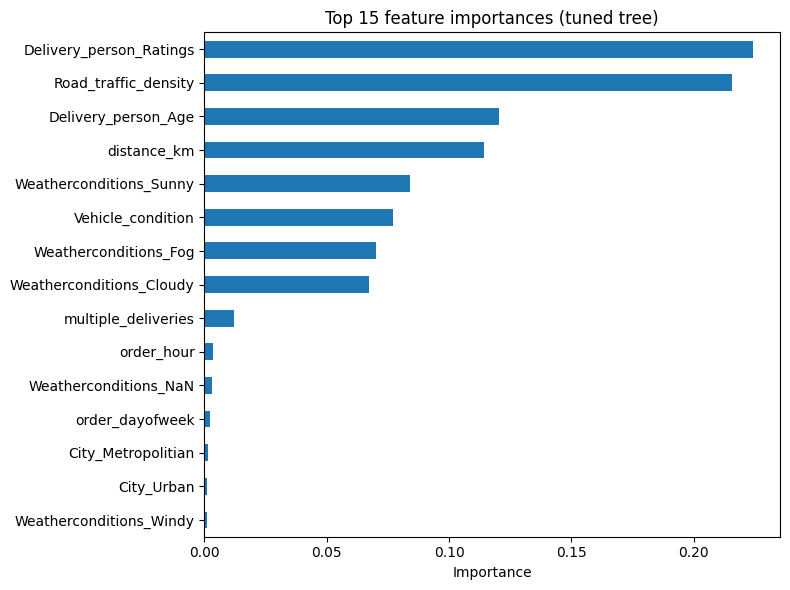

In [ ]:
imp = pd.Series(dt.feature_importances_, index=X_train_tree.columns).sort_values(ascending=False)
print(imp.head(15).round(4))

plt.figure(figsize=(8, 6))
imp.head(15).iloc[::-1].plot(kind="barh")
plt.xlabel("Importance"); plt.title("Top 15 feature importances (tuned tree)")
plt.tight_layout(); plt.show()

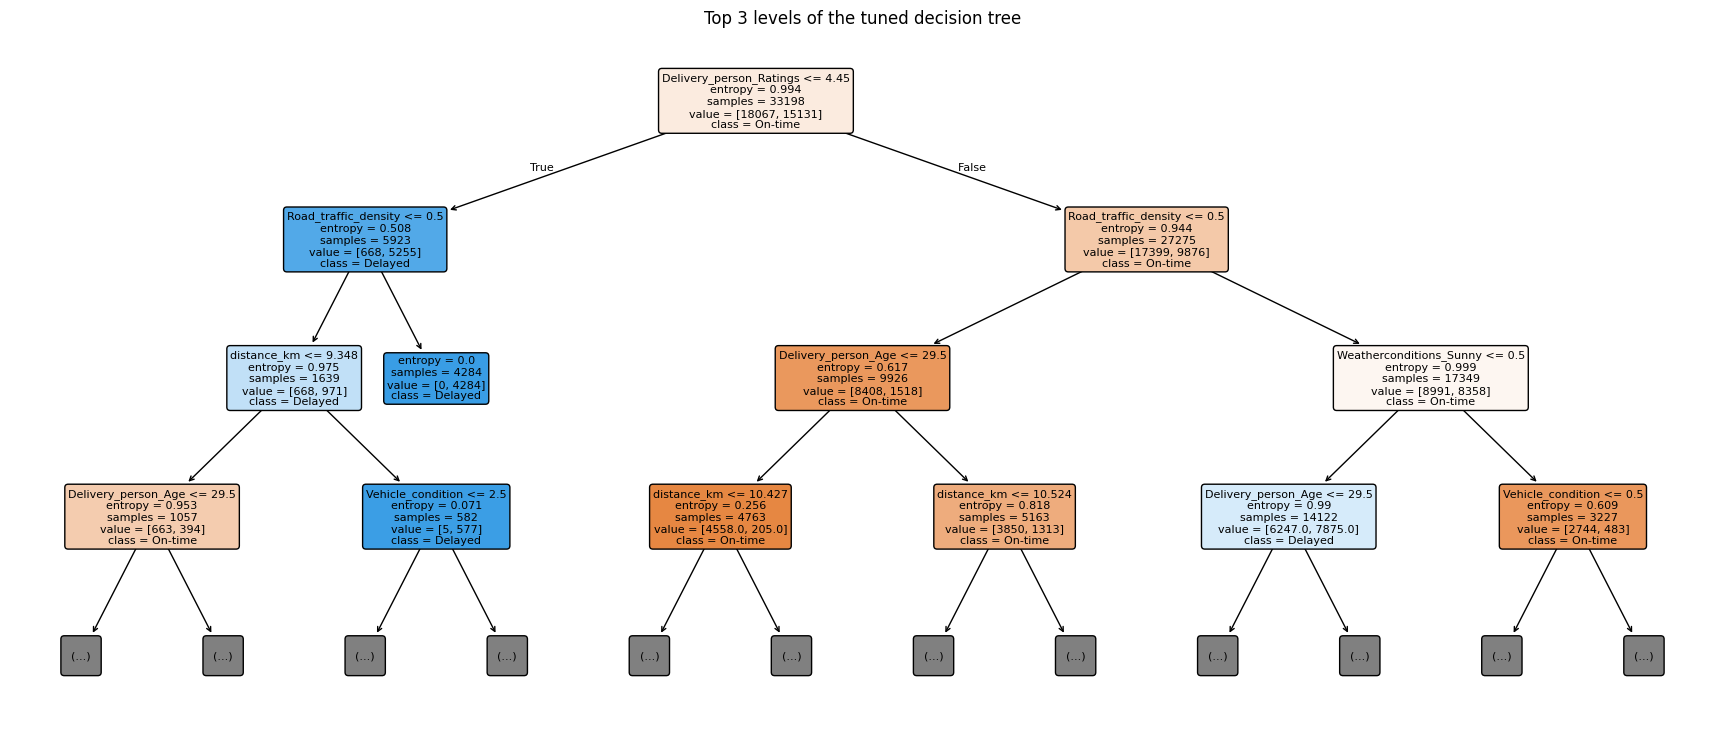

|--- Delivery_person_Ratings <= 4.45
|   |--- Road_traffic_density <= 0.50
|   |   |--- distance_km <= 9.35
|   |   |   |--- Delivery_person_Age <= 29.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- Delivery_person_Age >  29.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |--- distance_km >  9.35
|   |   |   |--- Vehicle_condition <= 2.50
|   |   |   |   |--- class: 1
|   |   |   |--- Vehicle_condition >  2.50
|   |   |   |   |--- class: 0
|   |--- Road_traffic_density >  0.50
|   |   |--- class: 1
|--- Delivery_person_Ratings >  4.45
|   |--- Road_traffic_density <= 0.50
|   |   |--- Delivery_person_Age <= 29.50
|   |   |   |--- distance_km <= 10.43
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- distance_km >  10.43
|   |   |   |   |--- truncated branch of depth 7
|   |   |--- Delivery_person_Age >  29.50
|   |   |   |--- distance_km <= 10.52
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- distance_km >  10.52
|   |

In [ ]:
plt.figure(figsize=(22, 9))
plot_tree(dt, max_depth=3, feature_names=X_train_tree.columns,
          class_names=["On-time", "Delayed"], filled=True, rounded=True, fontsize=8)
plt.title("Top 3 levels of the tuned decision tree")
plt.show()

print(export_text(dt, feature_names=list(X_train_tree.columns), max_depth=3))

In [ ]:
dt_small = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train_tree, y_clf_train)
print("Depth-3 tree test accuracy:", round(dt_small.score(X_test_tree, y_clf_test), 4))
print(export_text(dt_small, feature_names=list(X_train_tree.columns)))

Depth-3 tree test accuracy: 0.7372
|--- Delivery_person_Ratings <= 4.45
|   |--- Road_traffic_density <= 0.50
|   |   |--- distance_km <= 9.35
|   |   |   |--- class: 0
|   |   |--- distance_km >  9.35
|   |   |   |--- class: 1
|   |--- Road_traffic_density >  0.50
|   |   |--- class: 1
|--- Delivery_person_Ratings >  4.45
|   |--- Road_traffic_density <= 0.50
|   |   |--- Delivery_person_Age <= 29.50
|   |   |   |--- class: 0
|   |   |--- Delivery_person_Age >  29.50
|   |   |   |--- class: 0
|   |--- Road_traffic_density >  0.50
|   |   |--- Weatherconditions_Sunny <= 0.50
|   |   |   |--- class: 1
|   |   |--- Weatherconditions_Sunny >  0.50
|   |   |   |--- class: 0

